# Stream 2: Forecasting models (raw sales vs. corrected demand)

**Project:** Stockout-Aware Demand Forecasting for Grocery Retail (MIS 382N)

**The one question this notebook answers:** does training a forecasting model on *corrected demand* give better forecasts than training it on *recorded sales*?

**The plan, in plain English**
1. Load the 2,000-product sample and the corrected demand your teammate built.
2. Build "recent history" features (like sales one week ago) so the models have something to learn from.
3. Train the same models twice: once on recorded sales (**raw**), once on corrected demand (**corrected**).
4. Score both on the test week, using **in-stock days only** (when the shelf was never empty, we know what really sold).
5. Save the forecasts so streams 3, 4 and 5 can use them.

**Models:** seasonal naive (the simple baseline) and LightGBM (the main model, with forecast ranges). TFT goes in a separate notebook later.

**Decisions we made:** the corrected version uses corrected demand for *both* the target and the history features. Scoring is on in-stock days only. Forecast ranges (10th / 50th / 90th percentile) are included for the ordering simulation in stream 5.

## Step 0: Setup
Connect to Google Drive and pull the team's GitHub repo so we can use the shared code. You need the `GITHUB_TOKEN` secret turned on (key icon in the left sidebar), same as in the other notebooks.

In [18]:
# COLAB_ONLY
# Connect to Google Drive (that's where the shared data lives)
from google.colab import drive, userdata
import os
drive.mount('/content/drive')

# Download (or update) the team's code from GitHub so we can import from src/
token = userdata.get('GITHUB_TOKEN')
repo = 'stockout-aware-forecasting'
if not os.path.exists(f'/content/{repo}'):
    !git clone https://{token}@github.com/bulut19/{repo}.git /content/{repo}
%cd /content/{repo}
!git pull

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/stockout-aware-forecasting
Already up to date.


In [19]:
# Tools we'll use. Nothing special here: pandas for tables, numpy for math,
# lightgbm for the main model, matplotlib for charts.
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# The team's shared folders (set up in the README)
from src.load_data import DRIVE_DIR, PROC_DIR
from pathlib import Path
PROC_DIR = Path('/content/drive/MyDrive/Final Project/Stockout Project Data/processed')

# Settings in one place so they're easy to find and change later
SEED = 42
np.random.seed(SEED)

In [20]:
!pip install lightgbm

In [21]:
folder = '/content/drive/MyDrive/Final Project/Stockout Project Data/processed'
for name in sorted(os.listdir(folder)):
    print(name)

daily.parquet
daily_demand_v1.parquet
daily_model.parquet
hourly_demand_v1.parquet
sample_ids.csv


## Step 0b: Load the data
Two files do the work:
- `daily_demand_v1.parquet` has one row per product per day with recorded `sales`, estimated `demand` (corrected), `oos_hours` (empty-shelf hours that day) and `set` (train / valid / test). It only covers the 2,000-product sample.
- `daily_model.parquet` has the context for each day: discount, holidays, weather, day of week, category.

We join them into one table.

In [22]:
# Which 2,000 products are in the sample (the same ones every stream uses)
sample_ids = pd.read_csv(PROC_DIR / 'sample_ids.csv').series_id.tolist()

# The corrected-demand file (already limited to the 2,000 products)
dd = pd.read_parquet(PROC_DIR / 'daily_demand_v1.parquet')
dd['dt'] = pd.to_datetime(dd['dt'])

# The context file. We only load the columns we need (it's big: 4.85M rows),
# then keep just our 2,000 products.
context_cols = ['series_id', 'dt', 'day_of_week', 'discount', 'discount_missing',
                'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature',
                'avg_humidity', 'avg_wind_level', 'first_category_id']
ctx = pd.read_parquet(PROC_DIR / 'daily_model.parquet', columns=context_cols)
ctx['dt'] = pd.to_datetime(ctx['dt'])
ctx = ctx[ctx.series_id.isin(sample_ids)]

# Join the two tables: one row per product per day, sorted by product then date.
# Sorting matters: the "last week" features below rely on the rows being in date order.
base = dd.merge(ctx, on=['series_id', 'dt'], how='left')
base = base.sort_values(['series_id', 'dt']).reset_index(drop=True)
base['first_category_id'] = base['first_category_id'].astype('int64')

print(f"{len(base):,} rows | {base.series_id.nunique():,} products | "
      f"{base.dt.min().date()} to {base.dt.max().date()}")
base.head()

194,000 rows | 2,000 products | 2024-03-28 to 2024-07-02


,series_id,dt,sales,demand,lost_demand,oos_hours,set,zero_sales_day,day_of_week,discount,discount_missing,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level,first_category_id
0,0_193,2024-03-28,0.5,0.5,0.0,0,train,0,3,0.862,0,0,1,1.6999,15.48,73.54,1.97,8
1,0_193,2024-03-29,0.3,0.3,0.0,0,train,0,4,0.862,0,0,1,3.0190,15.08,76.56,1.71,8
2,0_193,2024-03-30,0.4,0.4,0.0,0,train,0,5,0.862,0,1,1,2.0942,15.91,76.47,1.73,8
3,0_193,2024-03-31,0.5,0.5,0.0,0,train,0,6,0.862,0,1,1,1.5618,16.13,77.40,1.76,8
4,0_193,2024-04-01,0.8,0.8,0.0,0,train,0,0,0.862,0,0,1,3.5386,15.37,78.26,1.25,8


In [23]:
# Quick safety checks, so we catch problems now instead of after an hour of training
days_per_product = base.groupby('series_id').size()
assert days_per_product.nunique() == 1, "Some products are missing days!"
print("Every product has", days_per_product.iloc[0], "days. Good.")

# The three date splits. These are frozen by the team: never train on valid or test.
print(base.groupby('set').dt.agg(['min', 'max', 'nunique']))

# Corrected demand should never be BELOW recorded sales (the notebook that built it guarantees this)
assert (base.demand >= base.sales - 1e-9).all(), "Corrected demand is below recorded sales somewhere"

# On days with no empty-shelf hours, corrected demand should equal recorded sales
in_stock = base.oos_hours == 0
print("In-stock days where demand != sales:", int((abs(base.demand[in_stock] - base.sales[in_stock]) > 1e-9).sum()))

Every product has 97 days. Good.
             min        max  nunique
set                                 
test  2024-06-26 2024-07-02        7
train 2024-03-28 2024-06-11       76
valid 2024-06-12 2024-06-25       14
In-stock days where demand != sales: 0


## Step 1: Build the "recent history" features
A forecasting model needs to see the recent past. We give it things like *"what did this product sell exactly one week ago?"*

**The important rule: nothing from the future.** We are forecasting a 7-day test week. On day 3 of that week we would not know yesterday's sales yet, because yesterday is also in the future. So every history feature looks back **at least 7 days**. That way every feature is something a real store would know on the day it makes the forecast.

**Raw vs. corrected.** We build the same features twice:
- **raw** version: history and target come from recorded `sales`
- **corrected** version: history and target come from corrected `demand`

Everything else (discount, holidays, weather, day of week, category) is identical. That's what makes the comparison fair: the only thing that changes is the data underneath.

In [24]:
def build_features(df, value_col):
    """
    Make one version of the modeling table.
    value_col is 'sales' (the raw version) or 'demand' (the corrected version).
    """
    d = df.copy()
    d['target'] = d[value_col]          # the thing the model learns to predict
    g = d.groupby('series_id')['target']

    # Sales exactly 1, 2 and 3 weeks ago (same weekday, so weekly patterns carry over)
    d['lag7']  = g.shift(7)
    d['lag14'] = g.shift(14)
    d['lag21'] = g.shift(21)

    # Average of the most recent 7 / 14 days we're allowed to see (starting 7 days back)
    d['roll7']  = g.transform(lambda s: s.shift(7).rolling(7,  min_periods=3).mean())
    d['roll14'] = g.transform(lambda s: s.shift(7).rolling(14, min_periods=7).mean())

    # Average of the same weekday over the last 3 weeks (a steadier version of lag7)
    d['dow_avg3'] = d[['lag7', 'lag14', 'lag21']].mean(axis=1)

    # The product's typical level, using TRAINING days only (never valid or test)
    train_mean = d[d.set == 'train'].groupby('series_id')['target'].mean()
    d['train_mean'] = d['series_id'].map(train_mean)
    return d

# The model will look at these columns. Notice there is no 'oos_hours' here:
# a store can't know in advance whether tomorrow will be a stockout day.
FEATURES = ['lag7', 'lag14', 'lag21', 'roll7', 'roll14', 'dow_avg3', 'train_mean',
            'day_of_week', 'discount', 'discount_missing', 'holiday_flag',
            'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity',
            'avg_wind_level', 'first_category_id']

data = {
    'raw':       build_features(base, 'sales'),
    'corrected': build_features(base, 'demand'),
}

# A peek at one product so you can see what the features look like
data['raw'].loc[data['raw'].series_id == data['raw'].series_id.iloc[0],
                ['dt', 'sales', 'lag7', 'lag14', 'roll7', 'set']].iloc[20:28]

,dt,sales,lag7,lag14,roll7,set
20,2024-04-17,0.0,0.8,0.4,0.514286,train
21,2024-04-18,0.2,0.6,0.1,0.585714,train
22,2024-04-19,0.2,0.5,0.7,0.557143,train
23,2024-04-20,0.8,0.8,0.4,0.614286,train
24,2024-04-21,1.1,0.3,0.3,0.614286,train
25,2024-04-22,0.5,0.0,0.7,0.514286,train
26,2024-04-23,0.4,0.9,0.6,0.557143,train
27,2024-04-24,0.4,0.0,0.8,0.442857,train


In [25]:
# Make sure no feature accidentally peeks at the future.
# For a product, lag7 on day t must equal that product's target on day t-7. Spot check:
d = data['raw']
one = d[d.series_id == d.series_id.iloc[0]].reset_index(drop=True)
assert np.allclose(one.lag7.iloc[7:], one.target.iloc[:-7]), "lag7 is not looking back 7 days!"
print("lag7 check passed: each day looks exactly 7 days back.")

# Rows with no lag7 are the first 7 days of the data. We don't train on those.
print("Rows without a lag7:", int(d.lag7.isna().sum()), "(first 7 days of each product)")

lag7 check passed: each day looks exactly 7 days back.
Rows without a lag7: 14000 (first 7 days of each product)


### Product groups (for the breakdown later)
We label each product **low / medium / high stockout** using only the *training* period, so no future information sneaks in. Later we check whether correcting demand helps more for products that stock out a lot.

In [26]:
# For each product: what share of training days had at least one empty-shelf hour?
train_days = base[base.set == 'train']
stockout_rate = (train_days.oos_hours > 0).groupby(train_days.series_id).mean()

# Split the products into three equal-sized groups: low, medium, high
bands = pd.qcut(stockout_rate.rank(method='first'), 3, labels=['low', 'medium', 'high'])
band_map = bands.astype(str).to_dict()

for v in data:
    data[v]['stockout_band'] = data[v]['series_id'].map(band_map)

print(stockout_rate.groupby(bands).mean().round(3).rename('avg stockout rate in training'))

oos_hours
low       0.296
medium    0.423
high      0.618
Name: avg stockout rate in training, dtype: float64


## Scoring helpers
Three numbers tell us how good a forecast is:
- **WAPE:** overall percent error. Lower is better. 0.30 means we're off by 30% of total sales.
- **MAE:** average miss in sales units.
- **Bias:** are we forecasting too high or too low? **Negative means under-forecasting**, which is the problem stockouts cause. 0 is ideal.

**We only score on in-stock days** (`oos_hours == 0`) and compare against *recorded sales*. On those days the shelf was never empty, so recorded sales are the real thing. On stockout days the true demand is unknown, so we don't grade there.

*The team README says to score with `src/metrics.py`. We define the same formulas here so the notebook is self-contained, then cross-check against the shared file if it has matching functions.*

In [27]:
def wape(actual, pred):
    # total absolute error, as a share of total actual sales
    return float(np.abs(actual - pred).sum() / np.abs(actual).sum())

def mae(actual, pred):
    # average miss, in sales units
    return float(np.abs(actual - pred).mean())

def bias(actual, pred):
    # (forecast total - actual total) / actual total. Negative = under-forecasting.
    return float((pred - actual).sum() / actual.sum())

def pinball(actual, pred_q, q):
    # Score for a forecast RANGE. Penalizes missing in the direction that matters for that percentile.
    diff = actual - pred_q
    return float(np.mean(np.maximum(q * diff, (q - 1) * diff)))

def score_table(fc, which_set, group_cols=('model', 'version')):
    """Score a forecast table on in-stock days of one split (valid or test)."""
    s = fc[(fc.set == which_set) & (fc.oos_hours == 0)]
    rows = []
    for key, g in s.groupby(list(group_cols)):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({**dict(zip(group_cols, key)),
                     'wape': wape(g.sales, g.forecast),
                     'mae': mae(g.sales, g.forecast),
                     'bias': bias(g.sales, g.forecast),
                     'n_days': len(g)})
    return pd.DataFrame(rows)

# Cross-check against the team's shared metrics file (if it has matching names)
try:
    from src import metrics as team_metrics
    print("Functions in src/metrics.py:", [n for n in dir(team_metrics) if not n.startswith('_')])
    a, p = np.array([1.0, 2.0, 3.0, 4.0]), np.array([1.5, 1.5, 3.5, 3.0])
    if hasattr(team_metrics, 'wape'):
        print("team wape:", team_metrics.wape(a, p), "| ours:", wape(a, p))
except Exception as e:
    print("Couldn't compare with src/metrics.py:", e)

Functions in src/metrics.py: ['bias', 'mae', 'np', 'pd', 'pinball', 'recovery_error', 'score', 'wape']
team wape: 0.25 | ours: 0.25


## Step 2: Seasonal naive (the baseline)
The simplest forecast there is: *"tomorrow will be the same as the same weekday last week."* No learning at all.

It matters because every fancier model has to beat it. We run it on both versions: the raw version copies last week's recorded sales, the corrected version copies last week's corrected demand.

In [28]:
FORECAST_SETS = ['valid', 'test']   # we forecast the validation and test weeks

def keep_columns(df, version, model, forecast):
    """Put a forecast into the standard layout everyone downstream will use."""
    out = df[['series_id', 'dt', 'set', 'sales', 'demand', 'oos_hours',
              'stockout_band', 'first_category_id']].copy()
    out['version'] = version
    out['model'] = model
    out['forecast'] = np.asarray(forecast)
    return out

all_forecasts = []

for version, df in data.items():
    rows = df[df.set.isin(FORECAST_SETS)]
    # Seasonal naive = just lag7 (same weekday, last week)
    all_forecasts.append(keep_columns(rows, version, 'seasonal_naive', rows['lag7']))

forecasts = pd.concat(all_forecasts, ignore_index=True)
print("Seasonal naive missing any forecast?", forecasts.forecast.isna().any())

naive_valid = score_table(forecasts, 'valid')
naive_test  = score_table(forecasts, 'test')
print("\nValidation (in-stock days):"); display(naive_valid.round(3))
print("Test (in-stock days):");       display(naive_test.round(3))

Seasonal naive missing any forecast? False

Validation (in-stock days):


,model,version,wape,mae,bias,n_days
0,seasonal_naive,corrected,0.414,0.430,0.068,15821
1,seasonal_naive,raw,0.422,0.438,-0.066,15821


Test (in-stock days):


,model,version,wape,mae,bias,n_days
0,seasonal_naive,corrected,0.384,0.455,0.103,8285
1,seasonal_naive,raw,0.385,0.457,-0.017,8285


In [29]:
# Save the baseline right away so streams 4 and 5 can start using it today.
# (We'll overwrite this file at the end with the full set of models.)
forecasts.to_parquet(PROC_DIR / 'forecasts_stream2_v1.parquet', index=False)
print("Saved baseline forecasts to forecasts_stream2_v1.parquet")

Saved baseline forecasts to forecasts_stream2_v1.parquet


## Step 3: LightGBM
LightGBM builds many small decision trees, each one fixing the mistakes of the ones before it. It learns patterns like *"sales jump on holidays"* and *"deeper discounts raise sales."*

**How we train it (and stay honest about it):**
- It learns from **training days only** (Mar 28 to Jun 11).
- We use the **validation days** (Jun 12 to 25) to decide when to stop training, so it doesn't memorize noise (overfitting).
- The **test week** is only used for the final score. The model never sees it.
- Raw and corrected versions use the **exact same settings**. Only the data differs.

In [30]:
# Settings for the main LightGBM model. Same for raw and corrected.
# 'tweedie' is a good fit for sales: never negative, lots of small numbers, some big ones.
MEAN_PARAMS = dict(objective='tweedie', n_estimators=1500, learning_rate=0.05,
                   num_leaves=63, min_child_samples=100, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)

def get_rows(df):
    """Split one version's table into train rows and valid/test rows."""
    train = df[(df.set == 'train') & df.lag7.notna()]   # skip first 7 days (no history yet)
    valid = df[df.set == 'valid']
    pred_rows = df[df.set.isin(FORECAST_SETS)]
    return train, valid, pred_rows

models = {}   # keep the trained models in case we want to inspect them

for version, df in data.items():
    train, valid, pred_rows = get_rows(df)

    model = lgb.LGBMRegressor(**MEAN_PARAMS)
    model.fit(train[FEATURES], train['target'],
              eval_set=[(valid[FEATURES], valid['target'])],      # used only to decide when to stop
              categorical_feature=['first_category_id'],
              callbacks=[lgb.early_stopping(50, verbose=False)])  # stop when validation stops improving
    models[('lgbm', version)] = model

    pred = np.clip(model.predict(pred_rows[FEATURES]), 0, None)   # sales can't be negative
    forecasts = pd.concat([forecasts, keep_columns(pred_rows, version, 'lightgbm', pred)],
                          ignore_index=True)
    print(f"{version:>9}: trained {model.best_iteration_} trees on {len(train):,} rows")

      raw: trained 102 trees on 138,000 rows
corrected: trained 90 trees on 138,000 rows


### Forecast ranges (for stream 5)
The ordering simulation needs more than one number. A store orders based on *how risky* a forecast is, so we also train models for the **10th, 50th and 90th percentile**. For example: *"most likely 10 units, but could be as low as 6 or as high as 15."*

In [31]:
QUANTILES = [0.1, 0.5, 0.9]
QUANT_PARAMS = dict(n_estimators=800, learning_rate=0.05, num_leaves=63,
                    min_child_samples=100, subsample=0.8, subsample_freq=1,
                    colsample_bytree=0.8, random_state=SEED, verbose=-1)

q_preds = []   # collect the range forecasts, then attach them to the table

for version, df in data.items():
    train, valid, pred_rows = get_rows(df)
    out = pred_rows[['series_id', 'dt']].copy()
    out['version'] = version

    for q in QUANTILES:
        m = lgb.LGBMRegressor(objective='quantile', alpha=q, **QUANT_PARAMS)
        m.fit(train[FEATURES], train['target'],
              eval_set=[(valid[FEATURES], valid['target'])],
              categorical_feature=['first_category_id'],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        out[f'q{int(q*100)}'] = m.predict(pred_rows[FEATURES])
        print(f"{version:>9} q{int(q*100):<2}: {m.best_iteration_} trees")

    # Each model is trained separately, so occasionally the 10th percentile
    # lands above the 50th. Sort each row so low <= middle <= high, and keep it >= 0.
    qs = np.sort(out[['q10', 'q50', 'q90']].to_numpy(), axis=1).clip(min=0)
    out[['q10', 'q50', 'q90']] = qs
    q_preds.append(out)

q_preds = pd.concat(q_preds, ignore_index=True)

# Attach the ranges to the LightGBM rows (the naive baseline has no ranges, so those stay empty)
forecasts = forecasts.merge(q_preds.assign(model='lightgbm'),
                            on=['series_id', 'dt', 'version', 'model'], how='left')
forecasts.groupby(['model', 'version'])[['forecast', 'q10', 'q50', 'q90']].mean().round(3)

      raw q10: 359 trees
      raw q50: 261 trees
      raw q90: 103 trees
corrected q10: 366 trees
corrected q50: 137 trees
corrected q90: 91 trees


forecast    q10   q50    q90
model          version                                
lightgbm       corrected     1.122  0.635  1.09  1.695
               raw           0.955  0.443  0.95  1.543
seasonal_naive corrected     1.228    NaN   NaN    NaN
               raw           1.057    NaN   NaN    NaN

## Step 4: Compare raw vs. corrected on the test week
This is the answer to the research question. All scores below are on **in-stock days only**, against recorded sales.

How to read the table:
- **WAPE / MAE:** lower is better.
- **Bias:** closer to 0 is better. Negative = the model under-forecasts.

In [32]:
valid_scores = score_table(forecasts, 'valid')
test_scores  = score_table(forecasts, 'test')

print("VALIDATION week (Jun 12 to 25), in-stock days"); display(valid_scores.round(3))
print("TEST week (Jun 26 to Jul 2), in-stock days");     display(test_scores.round(3))

VALIDATION week (Jun 12 to 25), in-stock days


,model,version,wape,mae,bias,n_days
0,lightgbm,corrected,0.351,0.364,0.021,15821
1,lightgbm,raw,0.365,0.379,-0.121,15821
2,seasonal_naive,corrected,0.414,0.430,0.068,15821
3,seasonal_naive,raw,0.422,0.438,-0.066,15821


TEST week (Jun 26 to Jul 2), in-stock days


,model,version,wape,mae,bias,n_days
0,lightgbm,corrected,0.350,0.415,-0.077,8285
1,lightgbm,raw,0.389,0.462,-0.211,8285
2,seasonal_naive,corrected,0.384,0.455,0.103,8285
3,seasonal_naive,raw,0.385,0.457,-0.017,8285


In [33]:
# Same thing, side by side: how much did correcting change each model?
pivot = test_scores.pivot(index='model', columns='version', values=['wape', 'mae', 'bias']).round(3)
pivot

wape              mae             bias       
version        corrected    raw corrected    raw corrected    raw
model                                                            
lightgbm           0.350  0.389     0.415  0.462    -0.077 -0.211
seasonal_naive     0.384  0.385     0.455  0.457     0.103 -0.017

In [34]:
# How good are the forecast RANGES? Two checks on the test week (in-stock days):
#  - pinball loss: lower is better
#  - coverage: how often did real sales land inside the 10th to 90th range? Ideal is about 80%.
t = forecasts[(forecasts.set == 'test') & (forecasts.oos_hours == 0) & (forecasts.model == 'lightgbm')]
rows = []
for version, g in t.groupby('version'):
    rows.append({'version': version,
                 'pinball_q10': pinball(g.sales, g.q10, 0.1),
                 'pinball_q50': pinball(g.sales, g.q50, 0.5),
                 'pinball_q90': pinball(g.sales, g.q90, 0.9),
                 'coverage_10_to_90': float(((g.sales >= g.q10) & (g.sales <= g.q90)).mean())})
pd.DataFrame(rows).round(3)

,version,pinball_q10,pinball_q50,pinball_q90,coverage_10_to_90
0,corrected,0.076,0.207,0.114,0.764
1,raw,0.084,0.223,0.135,0.749


### Does it help more for some products?
The same test-week scores, broken down by **stockout group** (products that stock out a little, some, or a lot) and by **category**. If correcting demand matters, we'd expect the biggest change for the high-stockout products.

In [35]:
# Scores by stockout group (low / medium / high), LightGBM only
by_band = score_table(forecasts[forecasts.model == 'lightgbm'], 'test',
                      group_cols=('stockout_band', 'version'))
by_band['stockout_band'] = pd.Categorical(by_band.stockout_band, ['low', 'medium', 'high'])
by_band = by_band.sort_values(['stockout_band', 'version'])
by_band.round(3)

,stockout_band,version,wape,mae,bias,n_days
2,low,corrected,0.389,0.344,-0.059,2985
3,low,raw,0.396,0.350,-0.155,2985
4,medium,corrected,0.364,0.344,-0.035,2858
5,medium,raw,0.377,0.355,-0.155,2858
0,high,corrected,0.319,0.587,-0.113,2442
1,high,raw,0.393,0.723,-0.278,2442


In [36]:
# Scores by category. We show the 10 biggest categories (by sales) so the table stays readable;
# the full list is saved to a file below.
by_cat_all = score_table(forecasts[forecasts.model == 'lightgbm'], 'test',
                         group_cols=('first_category_id', 'version'))
top_cats = (base.groupby('first_category_id').sales.sum().nlargest(10).index)
by_cat_all[by_cat_all.first_category_id.isin(top_cats)].sort_values(
    ['first_category_id', 'version']).round(3)

,first_category_id,version,wape,mae,bias,n_days
4,4,corrected,0.322,0.439,-0.133,1541
5,4,raw,0.371,0.507,-0.262,1541
6,5,corrected,0.605,0.653,-0.173,338
7,5,raw,0.593,0.640,-0.251,338
12,8,corrected,0.335,0.215,0.050,512
13,8,raw,0.342,0.219,-0.094,512
14,10,corrected,0.349,0.292,-0.050,488
15,10,raw,0.369,0.308,-0.219,488
26,16,corrected,0.370,0.244,0.113,1220
27,16,raw,0.351,0.232,-0.031,1220


### Charts
**Chart 1:** one example product over the validation and test weeks. Dots are recorded sales (red X = a day with an empty shelf). Lines are the raw and corrected forecasts. If the idea works, the corrected line sits higher on stockout days, where recorded sales were held down.

**Chart 2:** bias for each model, raw vs. corrected. Bars below zero mean under-forecasting.

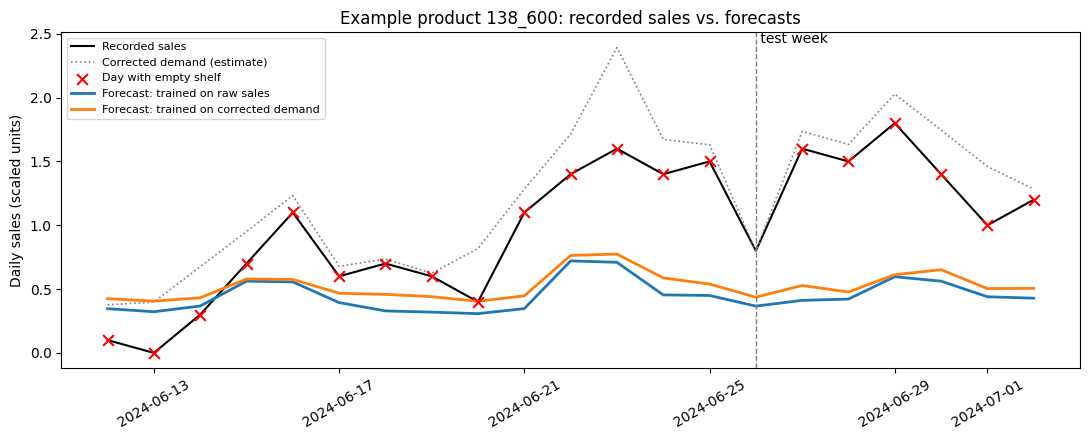

In [37]:
import os
os.makedirs('figures', exist_ok=True)

# Pick an example product: one that had stockouts on many forecast days and decent sales
fl = forecasts[(forecasts.model == 'lightgbm') & (forecasts.version == 'raw')]
per_series = fl.groupby('series_id').agg(stockout_days=('oos_hours', lambda s: (s > 0).sum()),
                                         avg_sales=('sales', 'mean'))
candidates = per_series[per_series.avg_sales >= per_series.avg_sales.median()]
example = candidates.stockout_days.idxmax()

ex = forecasts[(forecasts.series_id == example) & (forecasts.model == 'lightgbm')]
ex_raw  = ex[ex.version == 'raw'].sort_values('dt')
ex_corr = ex[ex.version == 'corrected'].sort_values('dt')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ex_raw.dt, ex_raw.sales, color='black', lw=1.5, label='Recorded sales')
ax.plot(ex_raw.dt, ex_raw.demand, color='gray', lw=1.2, ls=':', label='Corrected demand (estimate)')
so = ex_raw[ex_raw.oos_hours > 0]
ax.scatter(so.dt, so.sales, color='red', marker='x', s=60, zorder=5, label='Day with empty shelf')
ax.plot(ex_raw.dt,  ex_raw.forecast,  color='tab:blue',   lw=2, label='Forecast: trained on raw sales')
ax.plot(ex_corr.dt, ex_corr.forecast, color='tab:orange', lw=2, label='Forecast: trained on corrected demand')
ax.axvline(pd.Timestamp('2024-06-26'), color='gray', ls='--', lw=1); ax.text(pd.Timestamp('2024-06-26'), ax.get_ylim()[1], ' test week', va='top')
ax.set_title(f'Example product {example}: recorded sales vs. forecasts'); ax.set_ylabel('Daily sales (scaled units)')
ax.legend(fontsize=8, loc='upper left'); plt.xticks(rotation=30); plt.tight_layout()
plt.savefig('figures/stream2_example_product.png', dpi=150); plt.show()

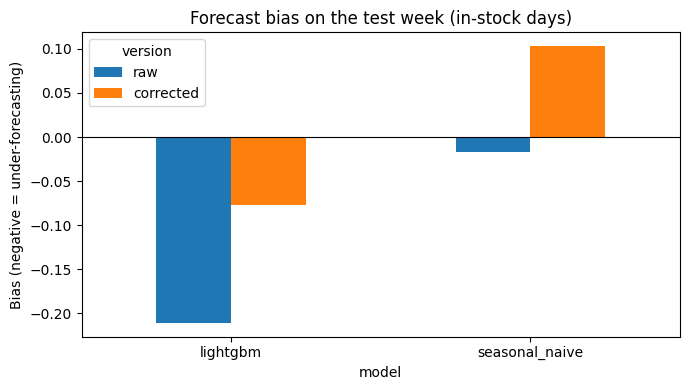

In [38]:
# Bias by model, raw vs. corrected (test week, in-stock days)
b = test_scores.pivot(index='model', columns='version', values='bias')[['raw', 'corrected']]
ax = b.plot(kind='bar', figsize=(7, 4), color=['tab:blue', 'tab:orange'])
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Bias (negative = under-forecasting)'); ax.set_title('Forecast bias on the test week (in-stock days)')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig('figures/stream2_bias.png', dpi=150); plt.show()

### How to read the results (important)
- Corrected demand is an **estimate**, not the truth. We never grade the models against it.
- On in-stock days, corrected demand equals recorded sales. But the corrected-trained model also *learned from* stockout days, where demand was lifted. It can't know in advance which days will be stockout days, so it forecasts somewhat higher everywhere. That can show up as a **positive bias** on in-stock days. That is not automatically "worse": it may be the model correctly expecting that a future day could hide extra demand. The ordering simulation (stream 5) is where we judge whether the higher forecasts are actually *useful*.
- Report cases where correcting does **not** help. The project plan says to.

## Step 5: Save everything for the team
Other streams load these files, so the layout matters:
- **`forecasts_stream2_v1.parquet`**: one row per product, day, model and version. Columns: `series_id`, `dt`, `set` (valid/test), `sales` (recorded), `demand` (corrected), `oos_hours`, `stockout_band`, `first_category_id`, `version` (raw/corrected), `model` (seasonal_naive/lightgbm), `forecast`, and `q10`, `q50`, `q90` (LightGBM only).
- **`results_stream2_v1.csv`**: the score tables.
- **`results_stream2_by_category_v1.csv`**: scores for every category.

In [39]:
forecasts.to_parquet(PROC_DIR / 'forecasts_stream2_v1.parquet', index=False)

results = pd.concat([valid_scores.assign(set='valid'), test_scores.assign(set='test')], ignore_index=True)
results.to_csv(PROC_DIR / 'results_stream2_v1.csv', index=False)
by_cat_all.to_csv(PROC_DIR / 'results_stream2_by_category_v1.csv', index=False)

print("Saved:", [f for f in ['forecasts_stream2_v1.parquet', 'results_stream2_v1.csv',
                              'results_stream2_by_category_v1.csv']])
print("Forecast table shape:", forecasts.shape)
forecasts.head()

Saved: ['forecasts_stream2_v1.parquet', 'results_stream2_v1.csv', 'results_stream2_by_category_v1.csv']
Forecast table shape: (168000, 14)


,series_id,dt,set,sales,demand,oos_hours,stockout_band,first_category_id,version,model,forecast,q10,q50,q90
0,0_193,2024-06-12,valid,0.5,0.500000,0,low,8,raw,seasonal_naive,0.5,NaN,NaN,NaN
1,0_193,2024-06-13,valid,0.4,0.692778,11,low,8,raw,seasonal_naive,0.5,NaN,NaN,NaN
2,0_193,2024-06-14,valid,0.2,0.200000,0,low,8,raw,seasonal_naive,0.4,NaN,NaN,NaN
3,0_193,2024-06-15,valid,0.8,0.884207,5,low,8,raw,seasonal_naive,0.9,NaN,NaN,NaN
4,0_193,2024-06-16,valid,0.5,0.500000,0,low,8,raw,seasonal_naive,0.6,NaN,NaN,NaN


In [40]:
# Final sanity check before handing off: every product has a forecast for every valid + test day, both versions
expected = base.series_id.nunique() * base.set.isin(FORECAST_SETS).groupby(base.dt).any().sum()
for (model, version), g in forecasts.groupby(['model', 'version']):
    assert len(g) == expected, f"{model}/{version}: {len(g)} rows, expected {expected}"
    assert g.forecast.notna().all()
print("Every model has a full set of forecasts. Ready to hand off.")

Every model has a full set of forecasts. Ready to hand off.


## Reuse and disclosure notes (for the final report)
- **Libraries (not pretrained models):** LightGBM, pandas, numpy, matplotlib.
- **Pretrained models used:** none in this notebook.
- **Borrowed code:** none intentionally. The data loading and setup follow the team's shared pattern (`src/load_data.py`, README).
- **LLM use:** this notebook was drafted with AI assistance. Before submitting, write 1 to 2 paragraphs on what the AI produced vs. what you decided and checked (the design choices above, e.g. 7-day lags, in-stock scoring, the corrected-lags decision).

## Next steps
- TFT (deep learning forecaster) goes in a separate notebook, `stream2_tft.ipynb`, using the same features and the same raw vs. corrected setup.
- Tell the team the forecast file name and columns so streams 3, 4 and 5 can load it.

In [ ]:
# COLAB_ONLY
# Save this notebook to the team's GitHub repo, on YOUR OWN branch (one branch per stream).
# Fill in your details, make sure the notebook is saved in Drive, then run this cell.
%cd /content/stockout-aware-forecasting
NAME  = 'john15young'                      # your GitHub username
EMAIL = 'john15young@icloud.com'   # use the email tied to your GitHub
NOTEBOOK_PATH = '/content/drive/MyDrive/Final Project/stream2_forecasting.ipynb'

!git config user.name "{NAME}"
!git config user.email "{EMAIL}"
!git checkout -B stream2-forecasting
!cp "{NOTEBOOK_PATH}" notebooks/stream2_forecasting.ipynb
!mkdir -p figures && git add notebooks/stream2_forecasting.ipynb figures/stream2_*.png
!git commit -m "Stream 2: seasonal naive and LightGBM, raw vs corrected demand"
!git push -u origin stream2-forecasting